In [46]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [47]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [48]:
print(data['target_names'])
print(data['feature_names'])

['malignant' 'benign']
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [49]:
df = pd.DataFrame(data.data,columns=data.feature_names)

In [50]:
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [51]:
df['target'] = data.target

In [52]:
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [53]:
sc = StandardScaler()
df[data.feature_names] = sc.fit_transform(df[data.feature_names])

In [54]:
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,2.489734,-0.565265,2.833031,2.487578,-0.214002,1.316862,0.724026,0.660820,1.148757,0.907083,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015,0
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,0.499255,-0.876244,0.263327,0.742402,-0.605351,-0.692926,-0.440780,0.260162,-0.805450,-0.099444,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190,0
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,1.228676,-0.780083,0.850928,1.181336,-0.297005,0.814974,0.213076,1.424827,0.237036,0.293559,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391,0
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,0.326373,-0.110409,0.286593,-0.288378,0.689702,2.744280,0.819518,1.115007,4.732680,2.047511,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010,0
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,1.270543,-0.790244,1.273189,1.190357,1.483067,-0.048520,0.828471,1.144205,-0.361092,0.499328,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,2.110995,0.721473,2.060786,2.343856,1.041842,0.219060,1.947285,2.320965,-0.312589,-0.931027,2.782080,0.071025,2.379583,2.604187,1.086384,0.191805,0.666001,2.067178,-1.138416,0.167980,1.901185,0.117700,1.752563,2.015301,0.378365,-0.273318,0.664512,1.629151,-1.360158,-0.709091,0
565,1.704854,2.085134,1.615931,1.723842,0.102458,-0.017833,0.693043,1.263669,-0.217664,-1.058611,1.300499,2.260938,1.156857,1.291565,-0.424010,-0.069758,0.252202,0.808431,-0.189161,-0.490556,1.536720,2.047399,1.421940,1.494959,-0.691230,-0.394820,0.236573,0.733827,-0.531855,-0.973978,0
566,0.702284,2.045574,0.672676,0.577953,-0.840484,-0.038680,0.046588,0.105777,-0.809117,-0.895587,0.184892,-0.257371,0.276693,0.180698,-0.379342,0.661277,0.510827,0.612157,-0.891416,0.036727,0.561361,1.374854,0.579001,0.427906,-0.809587,0.350735,0.326767,0.414069,-1.104549,-0.318409,0
567,1.838341,2.336457,1.982524,1.735218,1.525767,3.272144,3.296944,2.658866,2.137194,1.043695,1.157935,0.686088,1.438530,1.009503,-0.173000,2.017716,1.302285,0.785721,0.326634,0.904057,1.961239,2.237926,2.303601,1.653171,1.430427,3.904848,3.197605,2.289985,1.919083,2.219635,0


In [55]:
principal = PCA(n_components=3)
principal.fit(df[data.feature_names])
x = principal.transform(df[data.feature_names])
x.shape

(569, 3)

Text(0, 0.5, 'pc2')

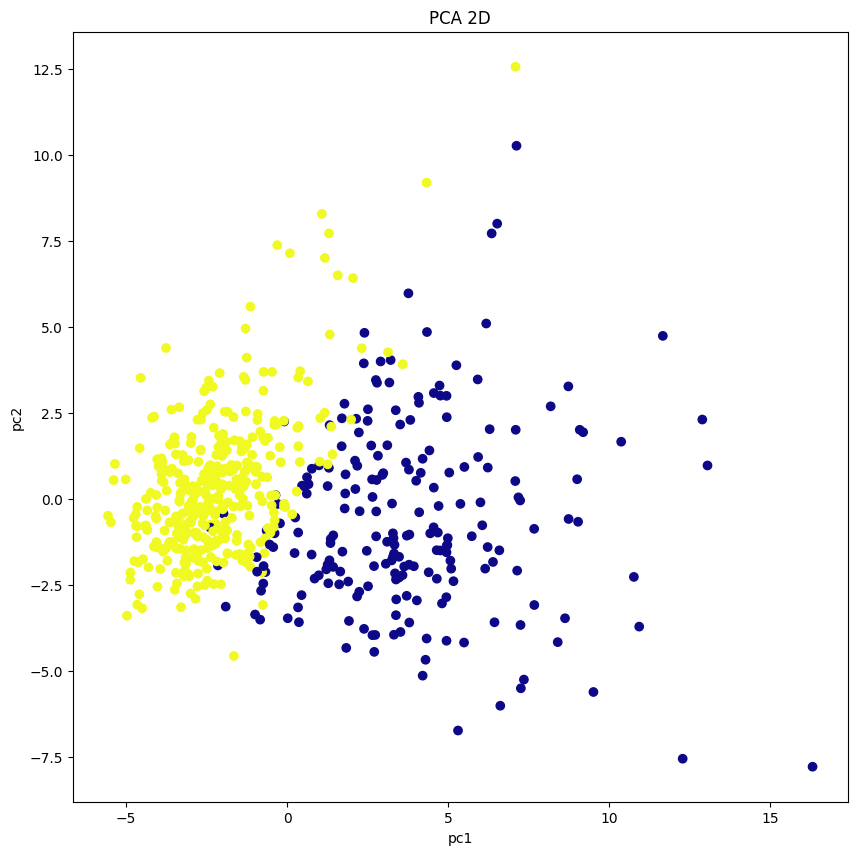

In [56]:
principal.components_
plt.figure(figsize=(10,10))
plt.title('PCA 2D')
plt.scatter(x[:,0],x[:,1],c=df['target'],cmap='plasma')
plt.xlabel('pc1')
plt.ylabel('pc2')

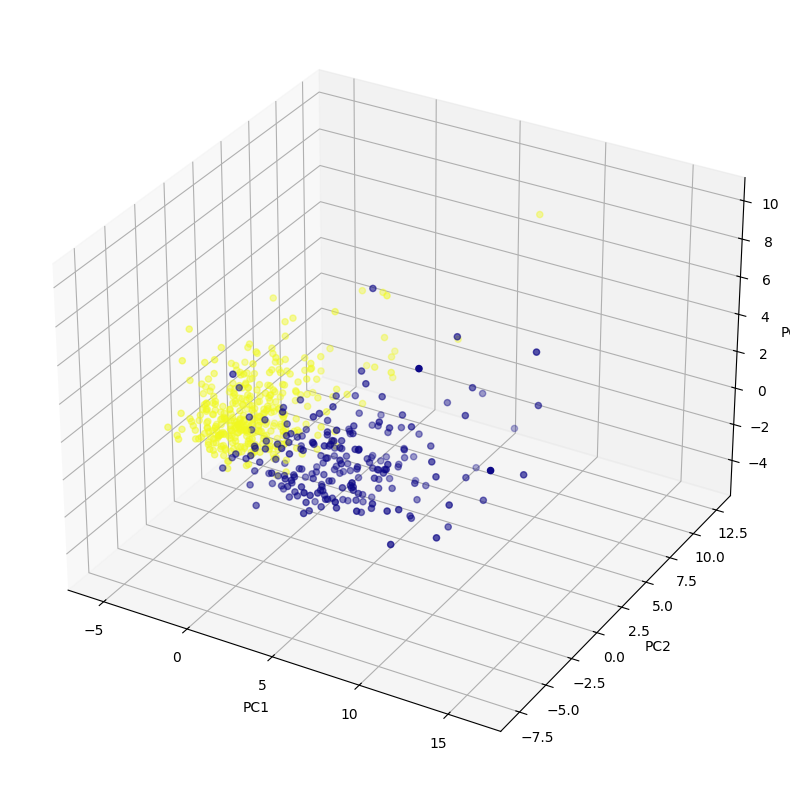

In [57]:
from mpl_toolkits.mplot3d import Axes3D
fig=plt.figure(figsize=(10,10))
axis=fig.add_subplot(111,projection='3d')
axis.scatter(x[:,0],x[:,1],x[:,2],c=df['target'],cmap='plasma')
axis.set_xlabel('PC1',fontsize=10)
axis.set_ylabel('PC2',fontsize=10)
axis.set_zlabel('PC3',fontsize=10)
plt.show()

In [58]:
print(principal.explained_variance_ratio_)

[0.44272026 0.18971182 0.09393163]


### Exercise 1

The dataset below contains 1,500 synthetic housing listings and includes asking price, property details, condition, and days on market. The analysis treats listings active for at least 180 days as unsold for six months. Since these data are synthetic, the results demonstrate the method and are not evidence about Maggie?s actual market.

#### Retrieve the dataset

This public domain dataset is available as a CSV from [Stratum?s housing market dataset page](https://stratumstats.com/datasets/housing-market/). Run the following cells with an internet connection.

In [59]:
housing = pd.read_csv(r"C:\Users\yugen\Desktop\SEM_5\Machine_Learning\housing_market.csv")
housing.head()

,ListingID,City,Neighborhood,PropertyType,Condition,Bedrooms,Bathrooms,SqFt,LotSize_sqft,Age_years,GarageSpaces,ListPrice,PricePerSqFt,DaysOnMarket,ListingDate
0,L00001,Riverside,Oakwood,Condo,Good,1,1.0,507,0,1,1,292438,576.80,9,2022-07-11
1,L00002,Riverside,Oakwood,Condo,Good,1,2.5,632,0,3,0,317167,501.85,62,2022-07-18
2,L00003,Crestwood,Lakeside,Condo,Fair,2,2.0,1094,0,2,0,314962,287.90,50,2023-04-22
3,L00004,Riverside,Eastside,Condo,Good,1,1.5,657,0,58,0,242939,369.77,9,2023-03-26
4,L00005,Dunmore,Cedar Ridge,Single Family,Fair,3,3.5,1784,4726,19,2,302631,169.64,32,2023-06-23


In [60]:
housing['Stale'] = housing['DaysOnMarket'] >= 180
print(f'Listings in dataset: {len(housing)}')
print(f"Listings active at least 180 days: {housing['Stale'].sum()} ({housing['Stale'].mean():.1%})")
display(housing.groupby('Stale')[['DaysOnMarket', 'ListPrice', 'PricePerSqFt', 'SqFt', 'Age_years', 'Bedrooms', 'Bathrooms', 'GarageSpaces']].median().round(1))
display(pd.crosstab(housing['Condition'], housing['Stale'], normalize='index').round(3))
display(pd.crosstab(housing['PropertyType'], housing['Stale'], normalize='index').round(3))

Listings in dataset: 1500
Listings active at least 180 days: 19 (1.3%)


,DaysOnMarket,ListPrice,PricePerSqFt,SqFt,Age_years,Bedrooms,Bathrooms,GarageSpaces
Stale,,,,,,,,
False,21.0,449393.0,304.0,1615.0,15.0,3.0,2.0,1.0
True,221.0,310708.0,249.8,1333.0,18.0,3.0,2.0,1.0


Stale,False,True
Condition,,
Excellent,1.000,0.000
Fair,0.981,0.019
Good,1.000,0.000
Poor,0.912,0.088


Stale,False,True
PropertyType,,
Condo,0.982,0.018
Multi-Family,0.990,0.010
Single Family,0.991,0.009
Townhouse,0.985,0.015


Variance explained: [0.446 0.194]


,PC1,PC2
Bedrooms,0.478,-0.017
Bathrooms,0.316,-0.031
SqFt,0.503,-0.024
LotSize_sqft,0.470,-0.001
Age_years,-0.011,-0.192
GarageSpaces,0.303,-0.028
ListPrice,0.264,0.663
PricePerSqFt,-0.191,0.722


,PC1,PC2
Stale,,
False,0.010,0.010
True,-0.741,-0.811


,PC1,PC2
SqFt,0.502507,0.024433
Bedrooms,0.478401,0.017192
LotSize_sqft,0.469723,0.000596


,PC1,PC2
PricePerSqFt,0.191306,0.722009
ListPrice,0.263830,0.662820
Age_years,0.011069,0.191760


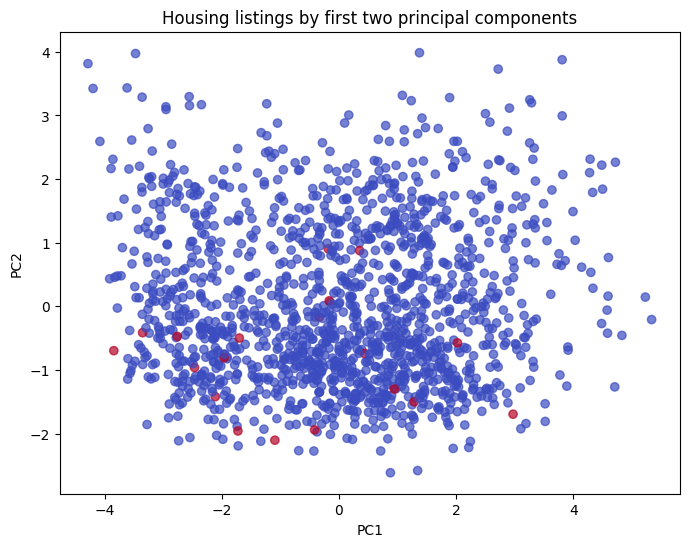

In [61]:
pca_features = ['Bedrooms', 'Bathrooms', 'SqFt', 'LotSize_sqft', 'Age_years', 'GarageSpaces', 'ListPrice', 'PricePerSqFt']
scaled_housing = StandardScaler().fit_transform(housing[pca_features])
housing_pca = PCA(n_components=2)
housing_scores = housing_pca.fit_transform(scaled_housing)
loadings = pd.DataFrame(housing_pca.components_.T, index=pca_features, columns=['PC1', 'PC2'])
print('Variance explained:', housing_pca.explained_variance_ratio_.round(3))
display(loadings.round(3))
housing['PC1'] = housing_scores[:, 0]
housing['PC2'] = housing_scores[:, 1]
display(housing.groupby('Stale')[['PC1', 'PC2']].mean().round(3))
display(loadings.abs().sort_values('PC1', ascending=False).head(3))
display(loadings.abs().sort_values('PC2', ascending=False).head(3))
plt.figure(figsize=(8, 6))
plt.scatter(housing['PC1'], housing['PC2'], c=housing['Stale'].astype(int), cmap='coolwarm', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Housing listings by first two principal components')
plt.show()

In [62]:
loadings = pd.DataFrame(
    {
        'PC1': [0.190, 0.544, 0.782, 0.365, 0.585, 0.394, 0.985, 0.520, 0.142],
        'PC2': [0.017, 0.020, -0.605, 0.294, 0.085, -0.273, 0.126, 0.402, 0.150],
        'PC3': [0.207, 0.204, 0.144, 0.585, 0.234, 0.027, -0.111, 0.519, 0.239]
    },
    index=['Climate', 'Housing', 'Health', 'Crime', 'Transportation', 'Education', 'Arts', 'Recreation', 'Economy']
)
strongest_loadings = pd.DataFrame({
    'Variable': [loadings[component].abs().idxmax() for component in loadings.columns],
    'Loading': [loadings.loc[loadings[component].abs().idxmax(), component] for component in loadings.columns]
}, index=loadings.columns)

print('Loadings:')
display(loadings)
print('Variable with the strongest absolute loading in each principal component:')
display(strongest_loadings)

Loadings:


,PC1,PC2,PC3
Climate,0.190,0.017,0.207
Housing,0.544,0.020,0.204
Health,0.782,-0.605,0.144
Crime,0.365,0.294,0.585
Transportation,0.585,0.085,0.234
Education,0.394,-0.273,0.027
Arts,0.985,0.126,-0.111
Recreation,0.520,0.402,0.519
Economy,0.142,0.150,0.239


Variable with the strongest absolute loading in each principal component:


,Variable,Loading
PC1,Arts,0.985
PC2,Health,-0.605
PC3,Crime,0.585
